
# Objectif  : Récupérer, traiter et conditionné les données NDVI Portugal en format Raster(tif)
- Conversion en csv

 Objectif  final : Construction Dataset Wild fire Portugal

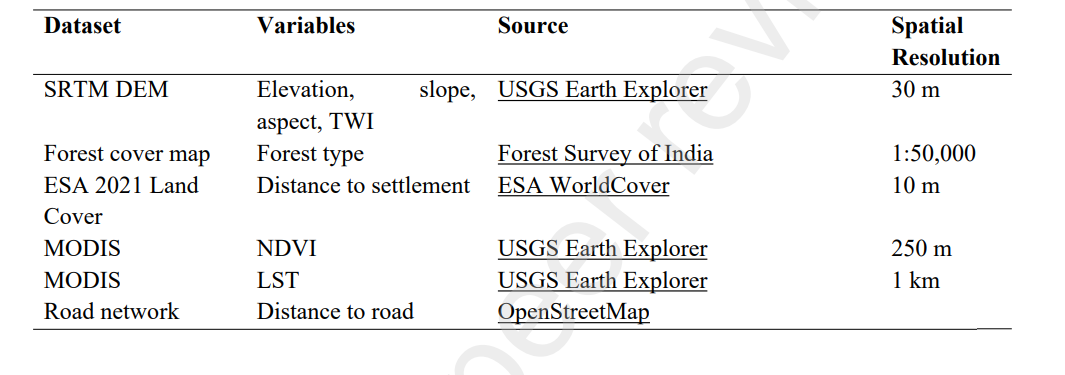

1. Imports



In [10]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from shapely.geometry import Point
from tqdm import tqdm

2. Montage Google Drive

  

In [11]:
from google.colab import drive
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


3. Chemins des fichiers



In [12]:
tiff_path_ndvi  = "//content/gdrive/MyDrive/Projet big data dossier organisé /dataBrute/NDVI_2020_1km_10-daily_V3_NDVI.tiff"
csv_path_grid   = "/content/gdrive/MyDrive/Projet big data dossier organisé /dataTraiter/grid_with_fire.csv"
output_csv_path = "/content/gdrive/MyDrive/Projet big data dossier organisé /dataTraiter/grid_with_fire_ndvi.csv"
border_file     = "/content/gdrive/MyDrive/Projet big data dossier organisé /dataBrute/pt/pt.shp"

4. Chargement de la grille CSV



In [13]:
print("1. Chargement de la grille CSV...")
df_ndvi = pd.read_csv(csv_path_grid)

1. Chargement de la grille CSV...


5. Extraction des valeurs NDVI par sondage



In [14]:
print("2. Ouverture du raster et préparation du sondage...")

with rasterio.open(tiff_path_ndvi) as src:
    raster_crs = src.crs
    nodata = src.nodata

    geometry = [Point(xy) for xy in zip(df_ndvi.longitude, df_ndvi.latitude)]
    gdf = gpd.GeoDataFrame(df_ndvi, geometry=geometry, crs="EPSG:4326")

    gdf_proj = gdf.to_crs(raster_crs)

    coords = [(geom.x, geom.y) for geom in gdf_proj.geometry]

    print(f"3. Extraction des valeurs pour {len(df_ndvi)} points...")
    ndvi_values = [val[0] for val in tqdm(src.sample(coords), total=len(coords))]

2. Ouverture du raster et préparation du sondage...
3. Extraction des valeurs pour 89198 points...


100%|██████████| 89198/89198 [00:07<00:00, 12602.13it/s]


6. Nettoyage et finalisation



In [15]:
print("4. Nettoyage des données...")

df_ndvi['ndvi_raw'] = ndvi_values

if nodata is not None:
    df_ndvi.loc[df_ndvi['ndvi_raw'] == nodata, 'ndvi_raw'] = np.nan

df_ndvi['ndvi_final'] = df_ndvi['ndvi_raw']

4. Nettoyage des données...



7. Sauvegarde en CSV



In [16]:
print(f"5. Sauvegarde vers : {output_csv_path}")
df_ndvi.to_csv(output_csv_path, index=False)

print(df_ndvi[['latitude', 'longitude', 'ndvi_final']].head())
print(f"Nombre de lignes traitées : {len(df_ndvi)}")

5. Sauvegarde vers : /content/gdrive/MyDrive/Projet big data dossier organisé /dataTraiter/grid_with_fire_ndvi.csv
    latitude  longitude  ndvi_final
0  36.987823  -7.963676    0.686275
1  36.994129  -8.952213    0.866667
2  36.996850  -7.974890    0.889726
3  37.003139  -8.952309    0.866667
4  37.003216  -8.941076    0.918118
Nombre de lignes traitées : 89198




8. Visualisation cartographique

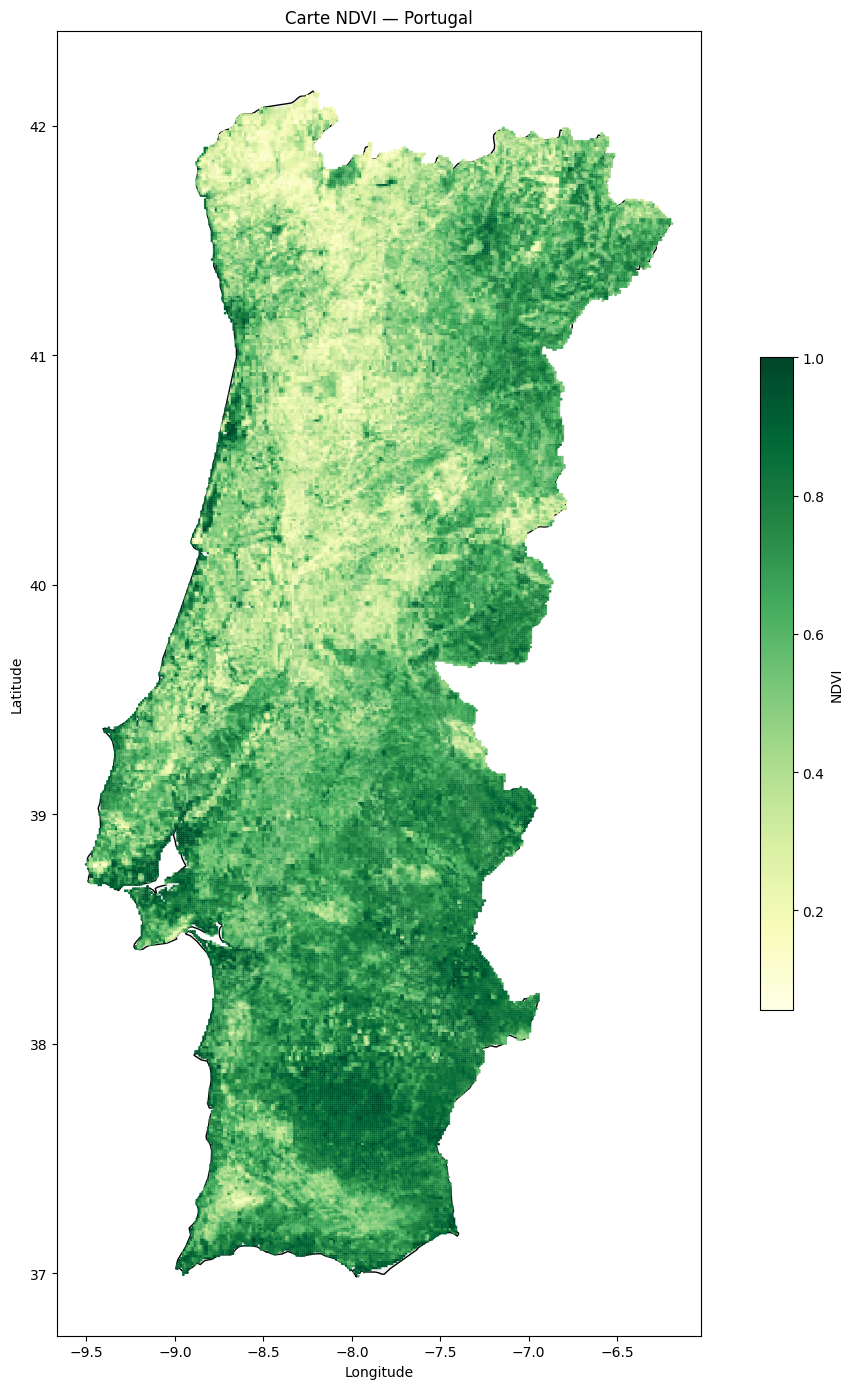

In [17]:
import matplotlib.pyplot as plt

gdf_map = gpd.GeoDataFrame(
    df_ndvi,
    geometry=gpd.points_from_xy(df_ndvi.longitude, df_ndvi.latitude),
    crs="EPSG:4326"
)

pt_boundary = gpd.read_file(border_file).to_crs(gdf_map.crs)

fig, ax = plt.subplots(figsize=(12, 14))

pt_boundary.plot(ax=ax, color='#f0f0f0', edgecolor='black', linewidth=1, zorder=1)

scatter = ax.scatter(
    gdf_map.geometry.x,
    gdf_map.geometry.y,
    c=gdf_map['ndvi_final'],
    cmap='YlGn',
    s=1,
    zorder=2
)

cbar = plt.colorbar(scatter, ax=ax, shrink=0.5)
cbar.set_label('NDVI')

plt.title("Carte NDVI — Portugal")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()